# Análise de desempenho — Etapa 2 (MPI)

Este caderno consolida os benchmarks MPI do Conjunto de Mandelbrot. Ele compara a decomposição por **faixas contíguas** (`block`) com a distribuição **cíclica por linhas** (`cyclic`), mede o custo de coleta e contrasta os resultados com OpenMP.

As métricas seguem a Aula 03: $S(n,p)=T(n)/T(n,p)$, $E(n,p)=S(n,p)/p$ e $FLB=(T_{max}-T_{min})/T_{max}$. Portanto, para o FLB, **0% é o balanceamento ideal**.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'README.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RESULTS = ROOT / 'results'
PLOTS = RESULTS / 'graficos'
TABLES = RESULTS / 'tabelas'
PLOTS.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13})
CORES = {'block': '#c44e52', 'cyclic': '#1f77b4', 'openmp': '#2ca02c'}
print(f'Diretório de resultados: {RESULTS.resolve()}')

Diretório de resultados: /home/enzosarmento/Documents/2026.2/processamento-paralelo/conjunto-de-mandelbrot/results


## Ambiente e método experimental

Os ensaios usam cinco repetições para cada $P\in[1,12]$, nos modos padrão (4096×4096, `MAX_ITER=1000`) e Seahorse (4096×4096, `MAX_ITER=5000`). O processador possui 6 núcleos físicos e 12 contextos lógicos por SMT. Logo, $P\leq12$ não caracteriza *oversubscription*; os pontos acima de 6 avaliam a contribuição dos contextos lógicos adicionais.

O tempo $T_p$ exclui a E/S dos arquivos. A implementação MPI sincroniza antes e depois da região medida, de modo que a janela termina quando o último processo conclui cálculo, coleta e eventual rearranjo.

In [2]:
ambiente = pd.DataFrame([
    ('CPU', 'AMD Ryzen 5 5600H with Radeon Graphics'),
    ('Núcleos físicos / contextos lógicos', '6 / 12 (SMT)'),
    ('Topologia', '1 nó NUMA; L3 de 16 MiB'),
    ('Compilador MPI', 'GCC/MPICH 13.3.0, -O3 -march=native -ffast-math'),
    ('Estratégias', 'block (faixas contíguas) e cyclic (round-robin por linhas)'),
    ('Repetições', '5 por configuração')
], columns=['Parâmetro', 'Configuração'])
display(ambiente)
ambiente.to_markdown(TABLES / 'tabela_mpi_ambiente.md', index=False)

,Parâmetro,Configuração
0,CPU,AMD Ryzen 5 5600H with Radeon Graphics
1,Núcleos físicos / contextos lógicos,6 / 12 (SMT)
2,Topologia,1 nó NUMA; L3 de 16 MiB
3,Compilador MPI,"GCC/MPICH 13.3.0, -O3 -march=native -ffast-math"
4,Estratégias,block (faixas contíguas) e cyclic (round-robin...
5,Repetições,5 por configuração


## Carregamento e normalização das métricas

Os CSVs guardam os tempos brutos por execução. O FLB é sempre recalculado abaixo usando $T_{max}$ e $T_{min}$, inclusive ao abrir CSVs antigos que tenham sido gerados antes da correção da fórmula.

In [3]:
def carregar_mpi(nome):
    df = pd.read_csv(RESULTS / nome)
    obrigatorias = {'processos', 'estrategia', 't1_s', 'tp_s', 't_max_s', 't_min_s', 't_comm_s'}
    faltantes = obrigatorias.difference(df.columns)
    if faltantes:
        raise ValueError(f'{nome}: colunas ausentes: {sorted(faltantes)}')
    df['fator_balanceamento'] = np.where(
        df['t_max_s'] > 0, (df['t_max_s'] - df['t_min_s']) / df['t_max_s'], 0.0)
    # Recalcular também as métricas derivadas evita inconsistência após nova coleta.
    df['speedup'] = df['t1_s'] / df['tp_s']
    df['eficiencia'] = df['speedup'] / df['processos']
    return df

df_padrao = carregar_mpi('benchmark_mpi_padrao.csv')
df_seahorse = carregar_mpi('benchmark_mpi_seahorse.csv')
print(f'Padrão: {len(df_padrao)} medições; Seahorse: {len(df_seahorse)} medições')
display(df_padrao.head())

Padrão: 120 medições; Seahorse: 120 medições


,modo,repeticao,processos,estrategia,t1_s,tp_s,t_max_s,t_min_s,t_avg_s,t_gather_s,t_reorder_s,t_comm_s,speedup,eficiencia,fator_balanceamento
0,padrao,1,1,block,0.845583,0.850742,0.814918,0.814918,0.814918,0.035821,0.000000,0.035821,0.993936,0.993936,0.000000
1,padrao,1,1,cyclic,0.845583,0.880403,0.806103,0.806103,0.806103,0.035443,0.038855,0.074298,0.960450,0.960450,0.000000
2,padrao,1,2,block,0.845583,0.447208,0.410732,0.410196,0.410464,0.036270,0.000000,0.036270,1.890805,0.945402,0.001305
3,padrao,1,2,cyclic,0.845583,0.479297,0.405070,0.404129,0.404599,0.034931,0.039146,0.074077,1.764215,0.882108,0.002323
4,padrao,1,3,block,0.845583,0.313628,0.277077,0.274160,0.275450,0.036369,0.000000,0.036369,2.696134,0.898711,0.010528


In [4]:
def agregar(df):
    return df.groupby(['estrategia', 'processos'], as_index=False).agg(
        t1_mean=('t1_s', 'mean'),
        tp_mean=('tp_s', 'mean'), tp_std=('tp_s', 'std'),
        speedup_mean=('speedup', 'mean'), speedup_std=('speedup', 'std'),
        eficiencia_mean=('eficiencia', 'mean'),
        flb_mean=('fator_balanceamento', 'mean'),
        tmax_mean=('t_max_s', 'mean'), tmin_mean=('t_min_s', 'mean'),
        gather_mean=('t_gather_s', 'mean'), reorder_mean=('t_reorder_s', 'mean'),
        comm_mean=('t_comm_s', 'mean')
    )

agg_padrao = agregar(df_padrao)
agg_seahorse = agregar(df_seahorse)
display(agg_padrao.head())

,estrategia,processos,t1_mean,tp_mean,tp_std,speedup_mean,speedup_std,eficiencia_mean,flb_mean,tmax_mean,tmin_mean,gather_mean,reorder_mean,comm_mean
0,block,1,0.846998,0.849205,0.004530,0.997435,0.009169,0.997435,0.000000,0.811861,0.811861,0.037341,0.0,0.037341
1,block,2,0.846998,0.451285,0.009104,1.877508,0.041441,0.938754,0.008066,0.413440,0.410088,0.037686,0.0,0.037686
2,block,3,0.846998,0.309364,0.002580,2.738023,0.027826,0.912674,0.003883,0.273189,0.272122,0.036030,0.0,0.036030
3,block,4,0.846998,0.351734,0.010281,2.409718,0.072030,0.602429,0.665399,0.313314,0.104818,0.038213,0.0,0.038213
4,block,5,0.846998,0.350282,0.008166,2.419176,0.061934,0.483835,0.922939,0.310254,0.023906,0.039762,0.0,0.039762


## Caso padrão

A tabela seleciona, para cada número de processos, a estratégia que obteve o menor $T_p$ médio.

In [5]:
def tabela_melhores(agg, nome):
    melhores = agg.loc[agg.groupby('processos')['tp_mean'].idxmin()].sort_values('processos').copy()
    exibir = melhores[['processos', 'estrategia', 'tp_mean', 'tp_std', 'speedup_mean',
                       'eficiencia_mean', 'flb_mean', 'comm_mean']].rename(columns={
        'processos': 'P', 'estrategia': 'Estratégia', 'tp_mean': 'Tp médio (s)',
        'tp_std': 'Desvio (s)', 'speedup_mean': 'Speedup',
        'eficiencia_mean': 'Eficiência', 'flb_mean': 'FLB', 'comm_mean': 'Tcomm (s)'})
    exibir.to_markdown(TABLES / f'tabela_mpi_melhores_{nome}.md', index=False, floatfmt='.6f')
    return exibir

melhores_padrao = tabela_melhores(agg_padrao, 'padrao')
display(melhores_padrao.style.format({'Eficiência': '{:.2%}', 'FLB': '{:.2%}'}))

,P,Estratégia,Tp médio (s),Desvio (s),Speedup,Eficiência,FLB,Tcomm (s)
0,1,block,0.849205,0.004530,0.997435,99.74%,0.00%,0.037341
1,2,block,0.451285,0.009104,1.877508,93.88%,0.81%,0.037686
2,3,block,0.309364,0.002580,2.738023,91.27%,0.39%,0.036030
15,4,cyclic,0.287270,0.005308,2.949314,73.73%,0.95%,0.079526
16,5,cyclic,0.254694,0.012705,3.332189,66.64%,2.74%,0.082089
17,6,cyclic,0.225580,0.003488,3.755390,62.59%,1.69%,0.084010
6,7,block,0.225105,0.009108,3.767585,53.82%,91.86%,0.039371
19,8,cyclic,0.214591,0.011481,3.955615,49.45%,12.97%,0.094435
20,9,cyclic,0.213505,0.011610,3.977057,44.19%,12.91%,0.106885
21,10,cyclic,0.219261,0.007657,3.867128,38.67%,13.85%,0.120084


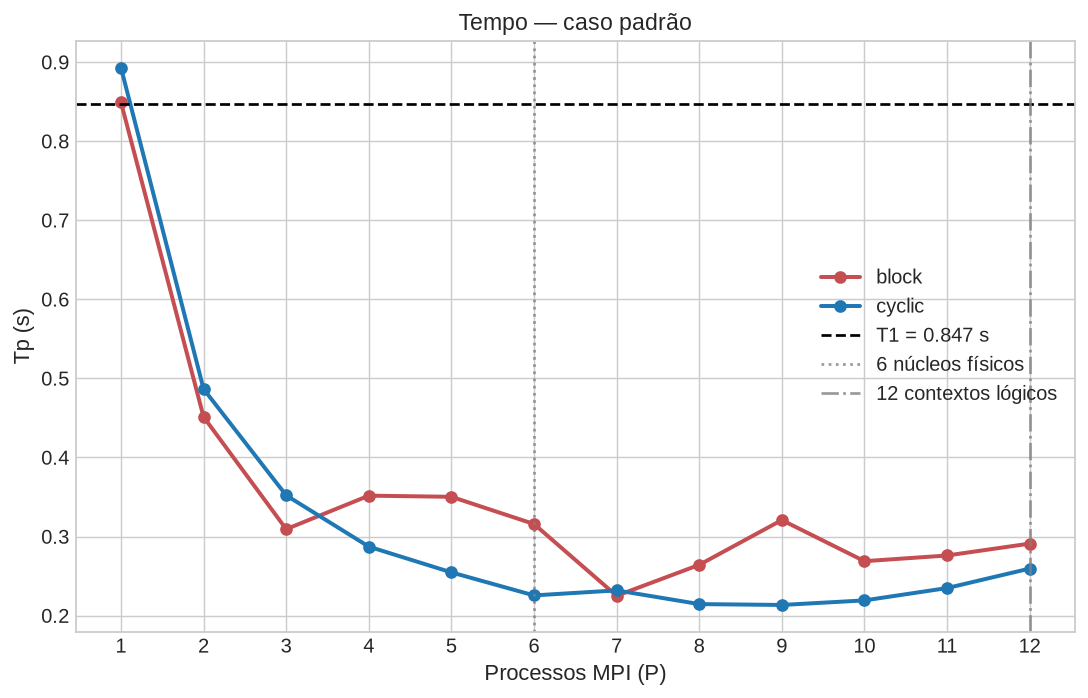

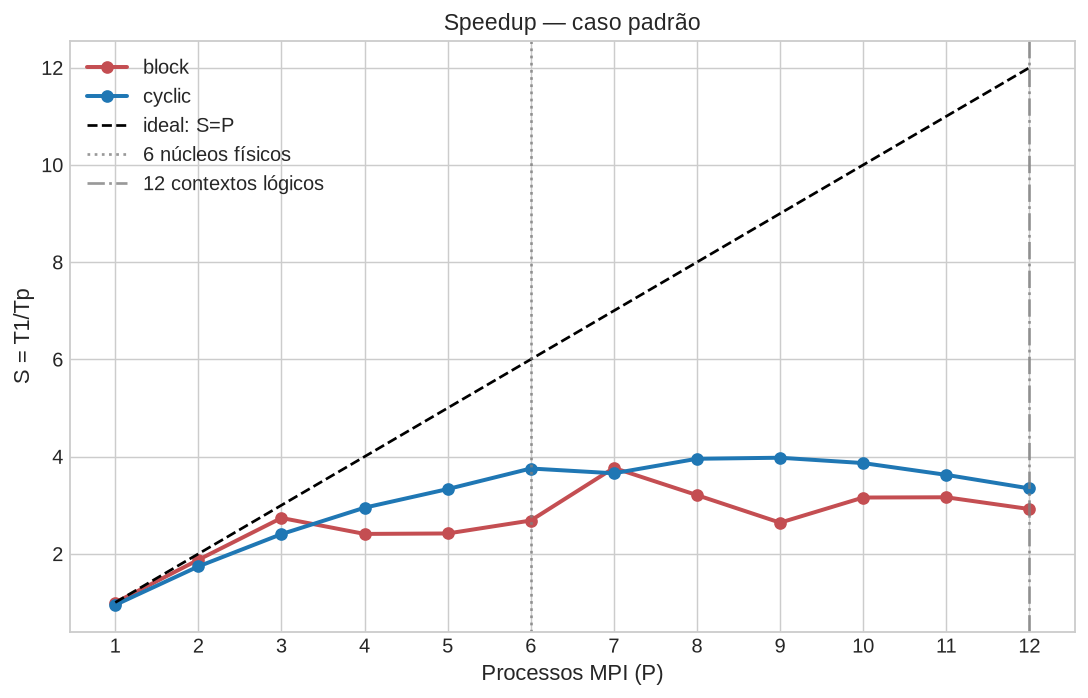

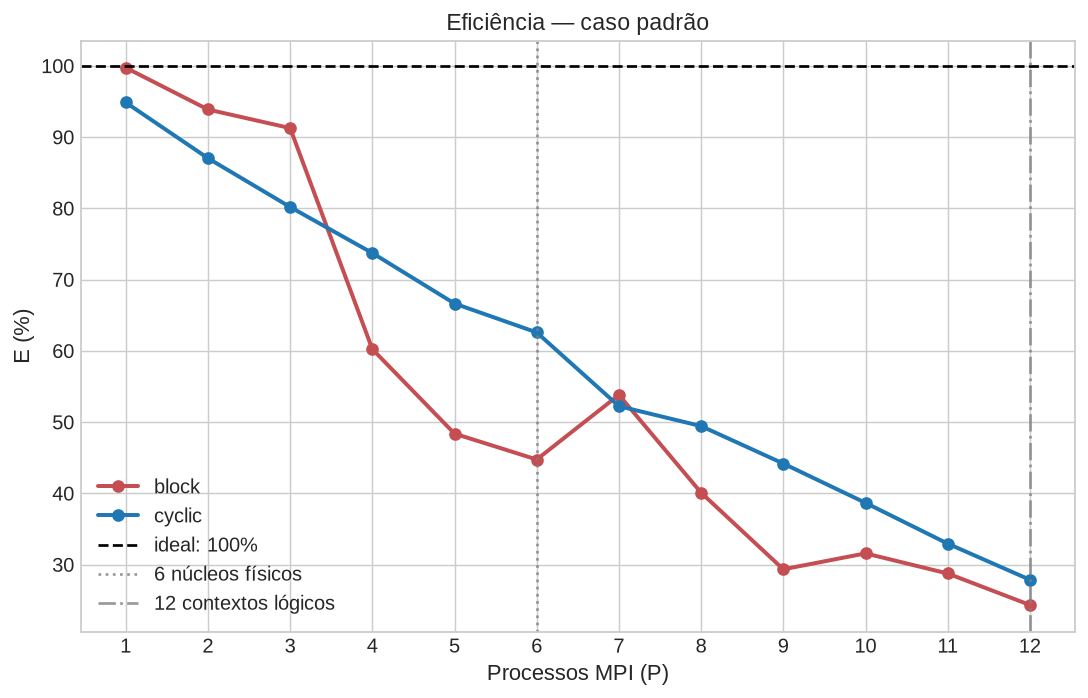

In [6]:
def marcar_hardware(ax):
    ax.axvline(6, color='gray', ls=':', alpha=.8, label='6 núcleos físicos')
    ax.axvline(12, color='gray', ls='-.', alpha=.8, label='12 contextos lógicos')

def curvas_desempenho(agg, titulo, prefixo_arquivo):
    processos = sorted(agg['processos'].unique())
    t1 = agg['t1_mean'].mean()
    graficos = {
        'tempo': ('Tempo', 'Tp (s)'),
        'speedup': ('Speedup', 'S = T1/Tp'),
        'eficiencia': ('Eficiência', 'E (%)'),
    }
    for metrica, (nome, ylabel) in graficos.items():
        fig, ax = plt.subplots(figsize=(8.5, 5.5))
        for estrategia, sub in agg.groupby('estrategia'):
            sub = sub.sort_values('processos')
            valores = sub['tp_mean'] if metrica == 'tempo' else (
                sub['speedup_mean'] if metrica == 'speedup' else sub['eficiencia_mean'] * 100)
            ax.plot(sub['processos'], valores, marker='o', lw=2.2,
                    color=CORES[estrategia], label=estrategia)
        if metrica == 'tempo':
            ax.axhline(t1, color='black', ls='--', label=f'T1 = {t1:.3f} s')
        elif metrica == 'speedup':
            ax.plot(processos, processos, color='black', ls='--', label='ideal: S=P')
        else:
            ax.axhline(100, color='black', ls='--', label='ideal: 100%')
        marcar_hardware(ax)
        ax.set(title=f'{nome} — {titulo}', xlabel='Processos MPI (P)', ylabel=ylabel)
        ax.set_xticks(processos)
        ax.legend()
        fig.tight_layout()
        fig.savefig(PLOTS / f'fig_mpi_{prefixo_arquivo}_{metrica}.png')
        plt.show()

curvas_desempenho(agg_padrao, 'caso padrão', 'padrao')

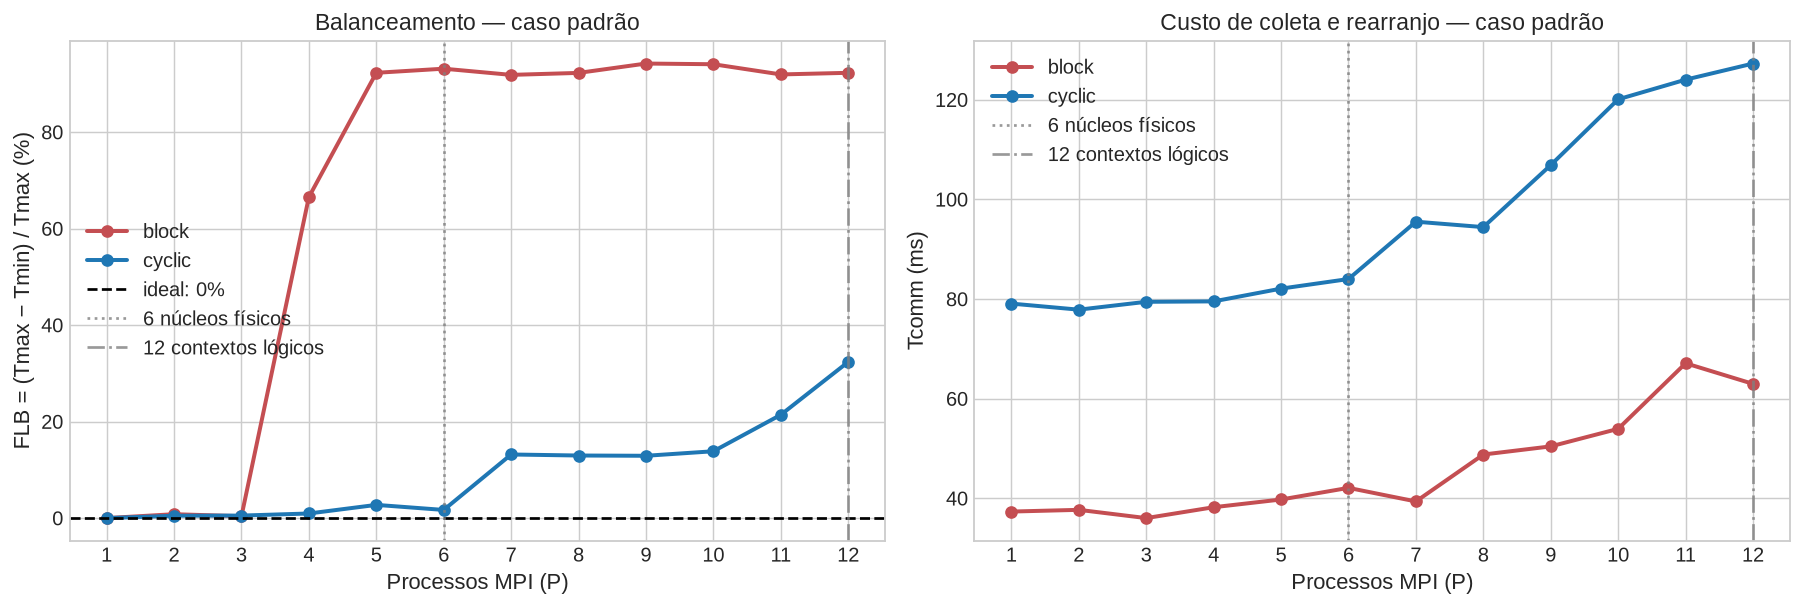

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for estrategia, sub in agg_padrao.groupby('estrategia'):
    sub = sub.sort_values('processos')
    ax1.plot(sub['processos'], sub['flb_mean'] * 100, marker='o', lw=2.2,
             color=CORES[estrategia], label=estrategia)
    ax2.plot(sub['processos'], sub['comm_mean'] * 1000, marker='o', lw=2.2,
             color=CORES[estrategia], label=estrategia)
ax1.axhline(0, color='black', ls='--', label='ideal: 0%')
for ax in (ax1, ax2):
    marcar_hardware(ax); ax.set_xticks(range(1, 13)); ax.legend()
ax1.set(title='Balanceamento — caso padrão', xlabel='Processos MPI (P)',
        ylabel='FLB = (Tmax − Tmin) / Tmax (%)')
ax2.set(title='Custo de coleta e rearranjo — caso padrão', xlabel='Processos MPI (P)',
        ylabel='Tcomm (ms)')
fig.tight_layout()
fig.savefig(PLOTS / 'fig_mpi_2_balanceamento_comunicacao_padrao.png')
plt.show()

## Vale dos Cavalos-Marinhos

O cenário Seahorse torna a heterogeneidade de custo mais visível. A comparação abaixo permite observar se o custo adicional do rearranjo cíclico é compensado pelo menor tempo ocioso.

,P,Estratégia,Tp médio (s),Desvio (s),Speedup,Eficiência,FLB,Tcomm (s)
0,1,block,3.104907,0.031220,0.996053,99.61%,0.00%,0.038870
13,2,cyclic,1.613742,0.008638,1.916340,95.82%,0.21%,0.081437
14,3,cyclic,1.108982,0.005362,2.788564,92.95%,0.35%,0.081625
15,4,cyclic,0.862299,0.006192,3.586381,89.66%,0.45%,0.083007
16,5,cyclic,0.718398,0.012646,4.305617,86.11%,0.64%,0.090379
17,6,cyclic,0.615297,0.008148,5.026594,83.78%,1.24%,0.086604
18,7,cyclic,0.576377,0.012441,5.367200,76.67%,7.44%,0.092956
19,8,cyclic,0.527070,0.011933,5.869678,73.37%,7.60%,0.101725
20,9,cyclic,0.486021,0.020417,6.371600,70.80%,8.31%,0.103811
21,10,cyclic,0.475758,0.017702,6.506798,65.07%,9.66%,0.116765


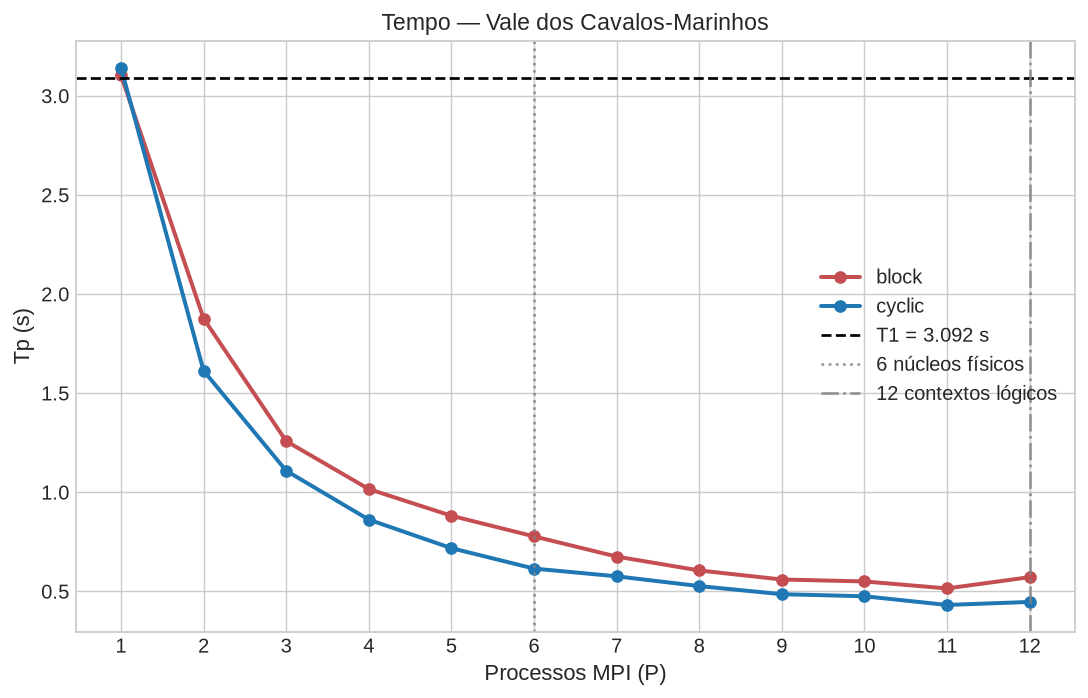

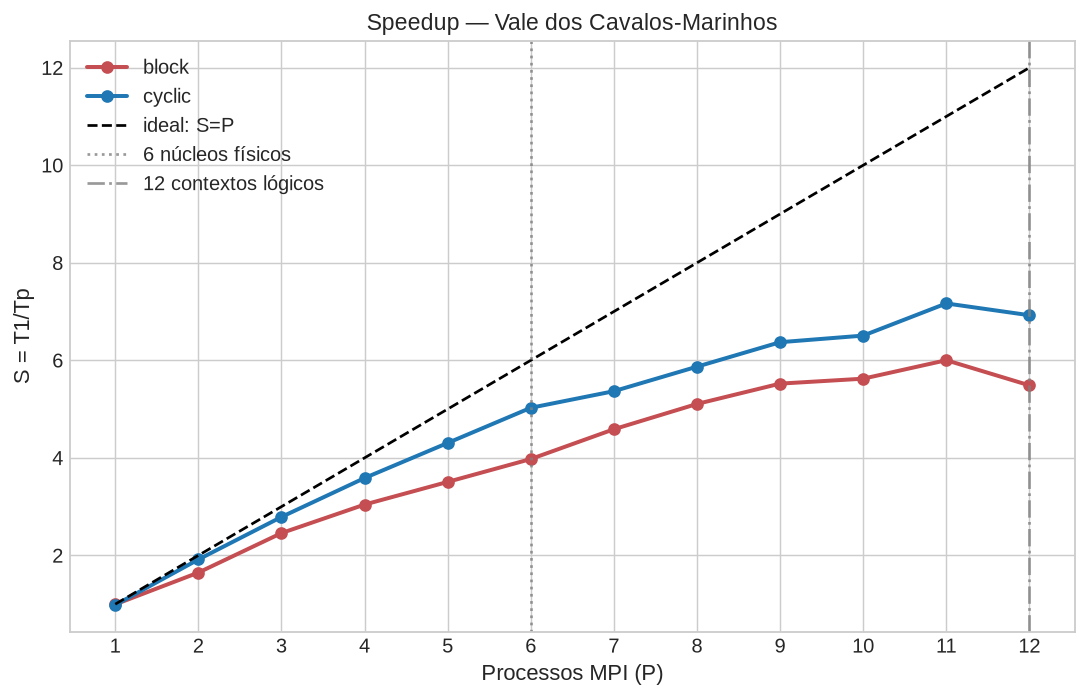

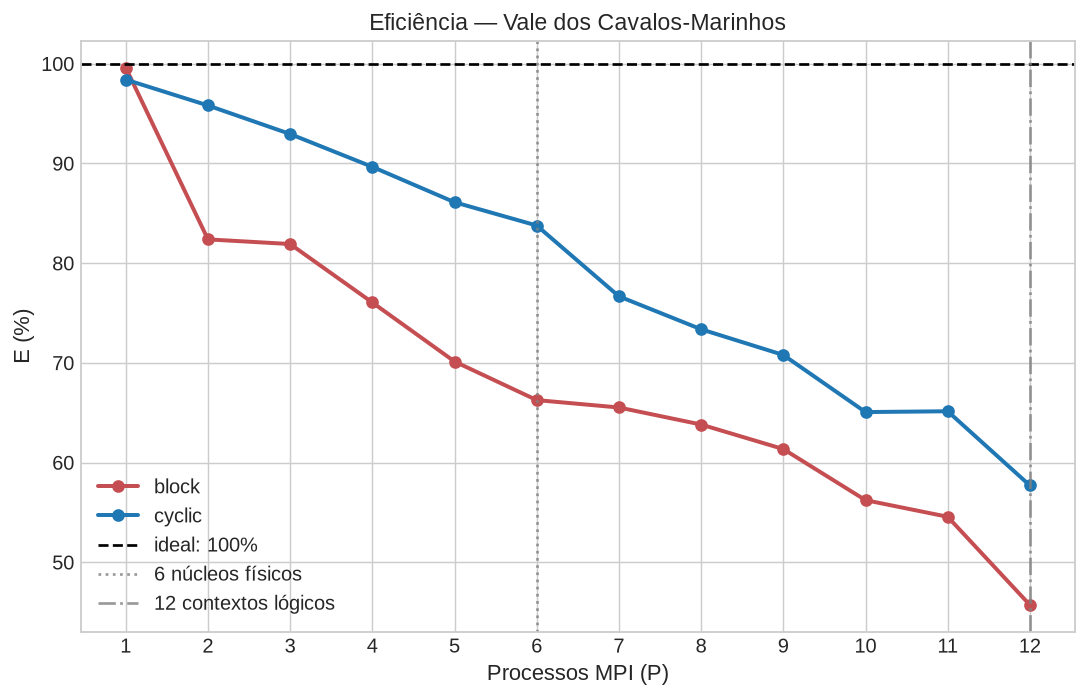

In [8]:
melhores_seahorse = tabela_melhores(agg_seahorse, 'seahorse')
display(melhores_seahorse.style.format({'Eficiência': '{:.2%}', 'FLB': '{:.2%}'}))
curvas_desempenho(agg_seahorse, 'Vale dos Cavalos-Marinhos', 'seahorse')

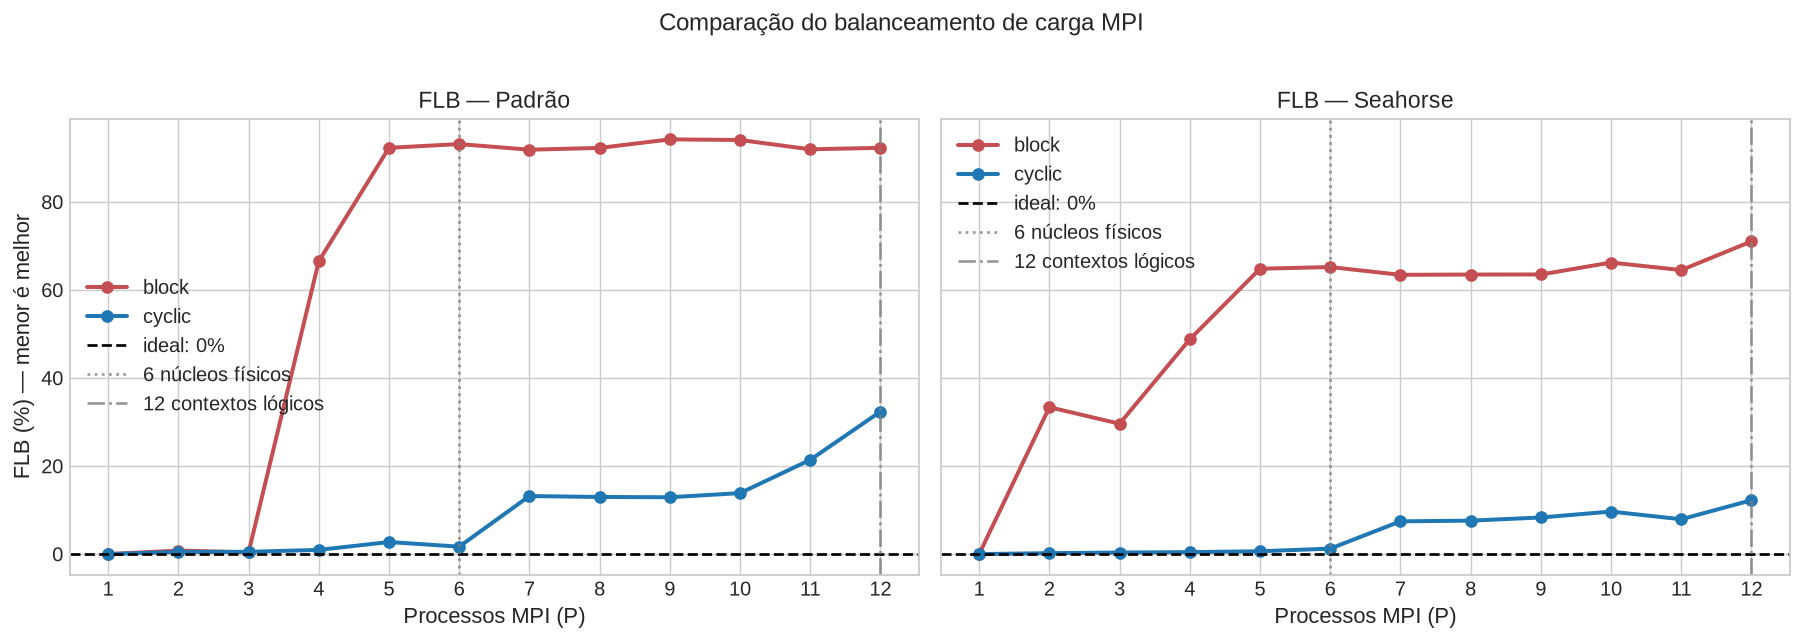

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, agg, titulo in zip(axes, (agg_padrao, agg_seahorse), ('Padrão', 'Seahorse')):
    for estrategia, sub in agg.groupby('estrategia'):
        sub = sub.sort_values('processos')
        ax.plot(sub['processos'], sub['flb_mean'] * 100, marker='o', lw=2.2,
                color=CORES[estrategia], label=estrategia)
    ax.axhline(0, color='black', ls='--', label='ideal: 0%')
    marcar_hardware(ax); ax.set(title=f'FLB — {titulo}', xlabel='Processos MPI (P)')
    ax.set_xticks(range(1, 13)); ax.legend()
axes[0].set_ylabel('FLB (%) — menor é melhor')
fig.suptitle('Comparação do balanceamento de carga MPI', y=1.02)
fig.tight_layout()
fig.savefig(PLOTS / 'fig_mpi_4_flb_padrao_seahorse.png')
plt.show()

## Comparação com OpenMP

A comparação é feita somente como contraste entre memória compartilhada e distribuída no mesmo computador. Para MPI, a referência $T_1$ é a execução do mesmo programa MPI com um processo; isso evita comparar a versão MPI com a otimização de simetria usada pela versão sequencial/OpenMP no caso padrão.

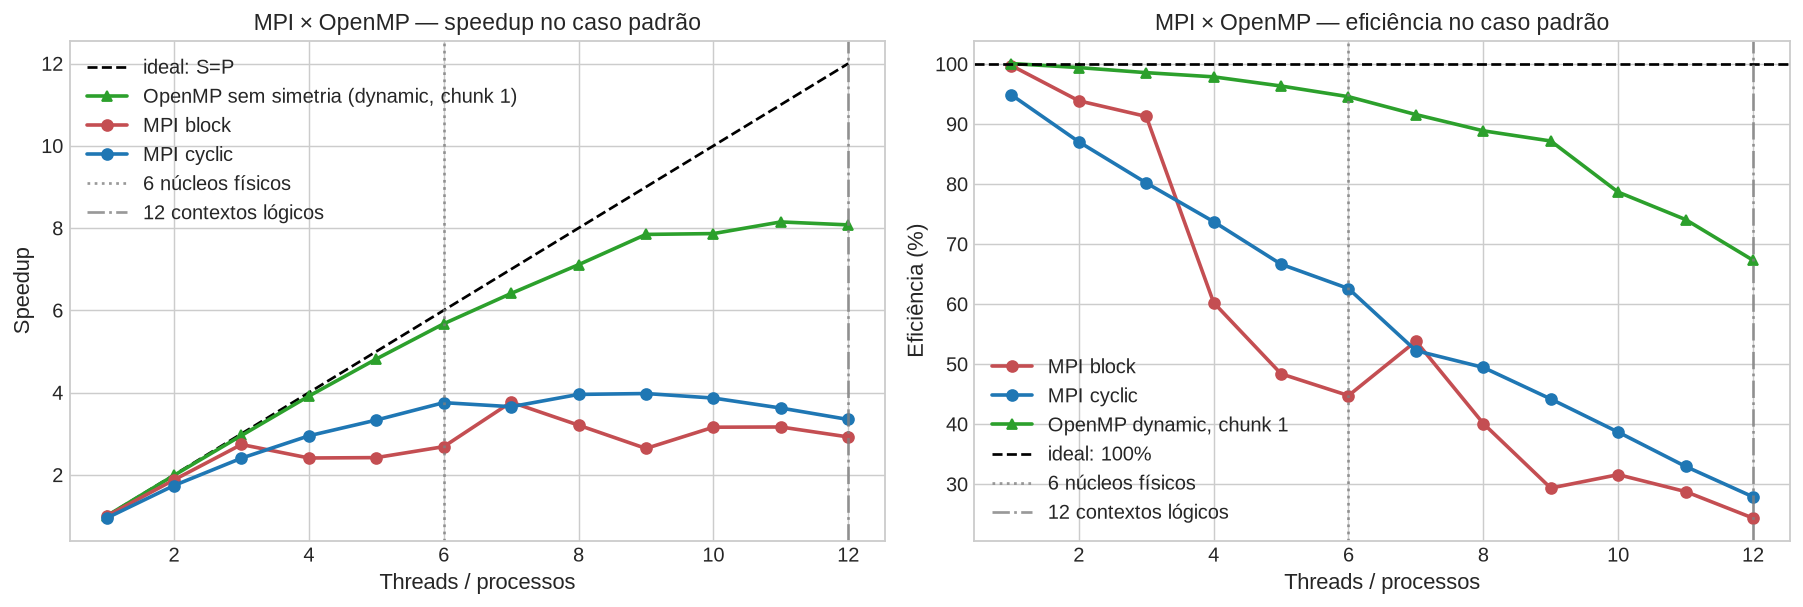

In [11]:
omp_padrao = pd.read_csv(RESULTS / 'benchmark_openmp_sem_simetria_padrao.csv')
omp_ref = (omp_padrao[(omp_padrao['escalonamento'] == 'dynamic') & (omp_padrao['chunk'] == 1)]
           .groupby('threads', as_index=False).agg(speedup=('speedup', 'mean'),
                                             eficiencia=('eficiencia', 'mean')))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
p = np.arange(1, 13)
ax1.plot(p, p, 'k--', label='ideal: S=P')
ax1.plot(omp_ref['threads'], omp_ref['speedup'], marker='^', lw=2, color=CORES['openmp'],
         label='OpenMP sem simetria (dynamic, chunk 1)')
for estrategia, sub in agg_padrao.groupby('estrategia'):
    ax1.plot(sub['processos'], sub['speedup_mean'], marker='o', lw=2,
             color=CORES[estrategia], label=f'MPI {estrategia}')
    ax2.plot(sub['processos'], sub['eficiencia_mean'] * 100, marker='o', lw=2,
             color=CORES[estrategia], label=f'MPI {estrategia}')
ax2.plot(omp_ref['threads'], omp_ref['eficiencia'] * 100, marker='^', lw=2, color=CORES['openmp'],
         label='OpenMP dynamic, chunk 1')
ax2.axhline(100, color='black', ls='--', label='ideal: 100%')
for ax, ylab in ((ax1, 'Speedup'), (ax2, 'Eficiência (%)')):
    marcar_hardware(ax); ax.set(xlabel='Threads / processos', ylabel=ylab); ax.legend()
ax1.set_title('MPI × OpenMP — speedup no caso padrão')
ax2.set_title('MPI × OpenMP — eficiência no caso padrão')
fig.tight_layout()
fig.savefig(PLOTS / 'fig_mpi_5_comparacao_openmp.png')
plt.show()

## Corretude, tempos por processo e escalabilidade fraca

As células abaixo leem os CSVs específicos do relatório. Gere-os com `collect_mpi_correctness.sh`, `benchmark_mpi.sh` e `benchmark_mpi_weak.sh` antes de executar esta seção.


In [12]:
arquivo_corretude = RESULTS / 'corretude_mpi.csv'
if arquivo_corretude.exists():
    corretude = pd.read_csv(arquivo_corretude)
    display(corretude)
    corretude.to_markdown(TABLES / 'tabela_mpi_corretude.md', index=False)
else:
    print('Execute: NP=4 ./scripts/collect_mpi_correctness.sh')


,caso,largura,altura,max_iter,processos,estrategia,igualdade_exata,pixels_divergentes,percentual_divergente,max_diferenca_iteracao,sha256_serial,sha256_mpi
0,padrao,4096,4096,1000,4,block,sim,0,0.0,0,e04b205a27e7abe0362d9f9410637c1718301b763bd034...,e04b205a27e7abe0362d9f9410637c1718301b763bd034...
1,padrao,4096,4096,1000,4,cyclic,sim,0,0.0,0,e04b205a27e7abe0362d9f9410637c1718301b763bd034...,e04b205a27e7abe0362d9f9410637c1718301b763bd034...
2,seahorse,4096,4096,5000,4,block,sim,0,0.0,0,5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe...,5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe...
3,seahorse,4096,4096,5000,4,cyclic,sim,0,0.0,0,5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe...,5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe...


In [13]:
arquivo_ranks = RESULTS / 'benchmark_mpi_seahorse_por_processo.csv'
if arquivo_ranks.exists():
    ranks = pd.read_csv(arquivo_ranks)
    tempos_ranks = (ranks.groupby(['estrategia', 'processos', 'rank'], as_index=False)
                   .agg(tempo_medio_s=('tempo_calculo_s', 'mean'),
                        tempo_dp_s=('tempo_calculo_s', 'std'), pixels=('pixels', 'first')))
    display(tempos_ranks)
    tempos_ranks.to_markdown(TABLES / 'tabela_mpi_seahorse_por_processo.md', index=False, floatfmt='.6f')
else:
    print('Execute: MODE_ARGS="--seahorse" RUNS=5 ./scripts/benchmark_mpi.sh')


,estrategia,processos,rank,tempo_medio_s,tempo_dp_s,pixels
0,block,1,0,3.066035,0.028160,16777216
1,block,2,0,1.839064,0.009232,8388608
2,block,2,1,1.225516,0.010191,8388608
3,block,3,0,1.221144,0.005494,5595136
4,block,3,1,1.003647,0.003009,5591040
...,...,...,...,...,...,...
151,cyclic,12,7,0.298544,0.023911,1396736
152,cyclic,12,8,0.298976,0.015376,1396736
153,cyclic,12,9,0.293599,0.020183,1396736
154,cyclic,12,10,0.287866,0.006520,1396736


In [14]:
arquivo_fraca = RESULTS / 'benchmark_mpi_escalabilidade_fraca.csv'
if arquivo_fraca.exists():
    fraca_mpi = pd.read_csv(arquivo_fraca)
    resumo_fraca = (fraca_mpi.groupby(['largura', 'altura', 'processos', 'estrategia'], as_index=False)
                    .agg(tp_medio_s=('tp_s', 'mean'), tp_dp_s=('tp_s', 'std'),
                         eficiencia_fraca=('eficiencia_fraca', 'mean'),
                         fbc=('fator_balanceamento', 'mean'),
                         comunicacao_s=('t_comm_s', 'mean')))
    display(resumo_fraca)
    resumo_fraca.to_markdown(TABLES / 'tabela_mpi_escalabilidade_fraca.md', index=False, floatfmt='.6f')
else:
    print('Execute: RUNS=3 ./scripts/benchmark_mpi_weak.sh')


,largura,altura,processos,estrategia,tp_medio_s,tp_dp_s,eficiencia_fraca,fbc,comunicacao_s
0,4096,4096,1,block,0.839781,0.004672,1.012566,0.000000,0.037695
1,4096,4096,1,cyclic,0.881870,0.002536,0.964212,0.000000,0.077847
2,8192,8192,4,block,1.374879,0.001022,0.618451,0.662067,0.148431
3,8192,8192,4,cyclic,1.121943,0.004346,0.757892,0.003400,0.303087
4,16384,16384,16,block,5.277780,0.515511,0.162071,0.933833,1.471326
5,16384,16384,16,cyclic,4.514869,0.568648,0.190501,0.397900,2.759760


## Síntese automática e reprodutibilidade

A distribuição cíclica tende a apresentar FLB menor em regiões do fractal cuja carga está concentrada em algumas faixas horizontais. Ela acrescenta comunicação e rearranjo no processo raiz; a melhor estratégia deve, portanto, ser escolhida pelo $T_p$ medido, e não apenas pelo FLB.

Para renovar os dados: `RUNS=5 PROCESSES="1 2 3 4 5 6 7 8 9 10 11 12" ./scripts/benchmark_mpi.sh` e `MODE_ARGS="--seahorse" RUNS=5 ./scripts/benchmark_mpi.sh`. Em seguida, execute todas as células deste notebook.

In [15]:
for nome, agg in [('Padrão', agg_padrao), ('Seahorse', agg_seahorse)]:
    melhor = agg.loc[agg['tp_mean'].idxmin()]
    print(f'{nome}: melhor configuração = {melhor.estrategia}, P={int(melhor.processos)}, '
          f'Tp={melhor.tp_mean:.6f} s, S={melhor.speedup_mean:.3f}, '
          f'E={melhor.eficiencia_mean:.2%}, FLB={melhor.flb_mean:.2%}.')

Padrão: melhor configuração = cyclic, P=9, Tp=0.213505 s, S=3.977, E=44.19%, FLB=12.91%.
Seahorse: melhor configuração = cyclic, P=11, Tp=0.431841 s, S=7.166, E=65.15%, FLB=7.91%.
